# Technical interview: Data Science, Operations Research & Applied AI

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alexandrerioo/scheduling_sandbox/blob/main/notebooks/technical_questions_applied_ai.ipynb)

Welcome! This notebook supports our conversation; it is **not** a test to finish on your own.

**How it works**
- **Part 1, Data Science & ML:** short real-life situations, each with a chart. We will go through them together.
- **Every question is folded.** Only unfold the ones the interviewer asks for: click the ▸ arrow left of the question
  title, or the *"cells hidden"* line under it.
- **Part 2, Operations Research:** one scheduling problem that we build up step by step.
- **Part 3, Applied AI:** one design question, on the same scheduling problem.
- The charts are already displayed: you don't need to run anything to discuss them.
- Some questions come with a small **optional coding exercise** (🧑‍💻). To run code, first run the **Setup** cell below (▶ button).
  Colab may warn that the notebook was not written by Google: click *Run anyway*. You can also use *Runtime → Run all*.
- Think out loud, ask clarifying questions, state your assumptions. Short answers are fine: we will dig in together.
- 🖊️ **Whiteboard:** for Part 2 we will paste an Excalidraw link in the Meet chat (no account needed).

**Context.** Imagine you are a *Forward-Deployed Engineer*: you work with industrial clients (factories)
to turn their data into better planning decisions. Today's client is a mid-size **machining plant**
(about 40 machines, 3,000 article references) that runs on an ERP.

In [1]:
# @title ⚙️ Setup: run this cell first (loads data and helper functions)
import os, tempfile, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import display

# ----------------------------------------------------------------- chart style
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY, INK, INK2, GRID, AXIS = "#898781", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
CRITICAL, LIGHT = "#d03b3b", "#f0efec"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 9.5, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2, "font.size": 9.5,
})

# ----------------------------------------------------------------- Part 1 data
def _ops_dataset(n=2500, seed=0):
    """Synthetic operations: features -> duration (min)."""
    rng = np.random.default_rng(seed)
    X = pd.DataFrame({
        "quantity": rng.lognormal(3.5, 0.7, n).round(),
        "diameter_mm": rng.uniform(10, 300, n),
        "material": rng.integers(0, 3, n),
        "machine_age_y": rng.uniform(0, 25, n),
        "tool_wear": rng.uniform(0, 1, n),
    })
    y = (8 + 0.15 * X.quantity + 0.12 * X.diameter_mm + 6 * X.material
         + 12 * X.tool_wear ** 2 + 0.002 * X.quantity * X.material * 10
         + rng.normal(0, 6, n) + rng.exponential(2, n))
    return X, y

# B1: a small sample of the client's machine-event log (200,000 rows)
SAMPLE_LOG_PATH = os.path.join(tempfile.gettempdir(), "machine_events_sample.csv")
if not os.path.exists(SAMPLE_LOG_PATH):
    _rng = np.random.default_rng(7)
    _n = 200_000
    pd.DataFrame({
        "timestamp": pd.date_range("2024-01-01", periods=_n, freq="37s").astype(str),
        "machine_id": _rng.choice([f"M-{k:02d}" for k in range(1, 13)], _n),
        "event": _rng.choice(["START", "STOP", "PART_DONE", "ALARM"], _n, p=[.2, .2, .55, .05]),
        "qty": _rng.integers(0, 20, _n),
        "spindle_rpm": _rng.normal(6000, 1500, _n).round(0),
    }).to_csv(SAMPLE_LOG_PATH, index=False)

# B2: recorded durations of one operation over 6 months
_rng = np.random.default_rng(3)
_n = 400
DURATION_DATES = pd.date_range("2025-09-01", "2026-02-28", periods=_n)
DURATIONS = _rng.normal(42, 4, _n).round(1)
_idx = _rng.permutation(_n)
DURATIONS[_idx[:7]] = _rng.uniform(85, 190, 7).round(1)   # long runs
DURATIONS[_idx[7:10]] = [-12.0, -35.0, -8.0]
DURATIONS[_idx[10:13]] = 0.0
DURATIONS[_idx[13:15]] = 9999.0
DURATIONS[_idx[15:19]] = _rng.normal(0.7, 0.05, 4).round(2)

# E3: weekly orders over two years
_rng = np.random.default_rng(11)
_weeks = pd.date_range("2024-01-01", "2025-12-29", freq="W-MON")
_t = np.arange(len(_weeks))
_wk = _weeks.isocalendar().week.to_numpy()
_orders = (420 + 0.9 * _t + 45 * np.sin(2 * np.pi * (_t - 8) / 52)
           - 170 * ((_wk >= 31) & (_wk <= 34)) - 200 * ((_wk >= 52) | (_wk <= 1))
           + 85 * (_weeks >= "2025-06-02") + _rng.normal(0, 22, len(_t)))
ORDERS_WEEKLY = pd.Series(_orders.round(), index=_weeks, name="orders")

def show_split(train_end=None, val_end=None):
    """Shade your train / validation / test periods on the weekly orders chart."""
    if train_end is None or val_end is None:
        print("👉 Set train_end and val_end (e.g. 'YYYY-MM-DD'), then run the cell again.")
        return
    train_end, val_end = pd.Timestamp(train_end), pd.Timestamp(val_end)
    s = ORDERS_WEEKLY
    parts = [("Train", s[s.index <= train_end], BLUE),
             ("Validation", s[(s.index > train_end) & (s.index <= val_end)], YELLOW),
             ("Test", s[s.index > val_end], ORANGE)]
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.plot(s.index, s.values, color=INK2, lw=1.4)
    for name, part, col in parts:
        if len(part):
            ax.axvspan(part.index.min() - pd.Timedelta(days=3), part.index.max() + pd.Timedelta(days=3),
                       color=col, alpha=0.18, lw=0, label=f"{name}: {len(part)} weeks")
    ax.set(title="Your split", ylabel="Orders per week")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=3)
    plt.show()

# F1: the quality model's test-set predictions (1 = defective)
Y_TRUE_QC = np.r_[np.ones(100, int), np.zeros(9900, int)]
Y_PRED_QC = np.r_[np.ones(10, int), np.zeros(90, int), np.ones(10, int), np.zeros(9890, int)]

# ----------------------------------------------------------------- exercise checks
def check_chunks(fn):
    got = fn(SAMPLE_LOG_PATH, chunksize=50_000)
    if got is None or len(got) == 0:
        print("⏳ Not implemented yet: `totals` is still empty.")
        return
    expected = pd.read_csv(SAMPLE_LOG_PATH, usecols=["machine_id", "qty"]).groupby("machine_id")["qty"].sum()
    got = pd.Series(got).sort_index()
    if got.index.equals(expected.index) and np.allclose(got.values, expected.values):
        print("✅ Correct: same totals as reading the whole file at once.")
        display(got.to_frame("total_qty").T)
    else:
        print("❌ Not quite. Expected (first rows):")
        display(pd.DataFrame({"expected": expected, "yours": got}).head())

def check_iqr(fn):
    x1 = np.array([12, 13, 12, 14, 13, 15, 12, 13, 14, 60, -20, 13])
    x2 = np.array([12, 13, 12, 14, 13, 15, 12, 13, 14, 19, -20, 13])
    tests = [(x1, 1.5, [9, 10]), (x2, 1.5, [9, 10]), (x2, 3.0, [10])]
    for x, k, expected in tests:
        got = np.asarray(fn(x, k=k), dtype=bool)
        if not got.any():
            print("⏳ Not implemented yet (nothing is flagged).")
            return
        if sorted(np.flatnonzero(got).tolist()) != expected:
            print(f"❌ For x = {x.tolist()} and k = {k}: expected outliers at positions {expected}, "
                  f"got {np.flatnonzero(got).tolist()}.")
            return
    flags = np.asarray(fn(DURATIONS), dtype=bool)
    print(f"✅ Correct. On the durations of the chart above, your rule flags {flags.sum()} of {len(flags)} points:")
    print(sorted(DURATIONS[flags].round(1).tolist()))

def check_precision_recall(fn):
    yt = np.array([1, 0, 1, 1, 0, 0, 1, 0])
    yp = np.array([1, 0, 0, 1, 1, 0, 0, 0])
    p, r = fn(yt, yp)
    if p is None or r is None:
        print("⏳ Not implemented yet.")
        return
    if not (np.isclose(p, 2 / 3) and np.isclose(r, 0.5)):
        print(f"❌ On y_true={yt.tolist()}, y_pred={yp.tolist()}: expected precision 0.667 and recall 0.5, "
              f"got {p:.3f} and {r:.3f}.")
        return
    p, r = fn(Y_TRUE_QC, Y_PRED_QC)
    print(f"✅ Correct. On the quality model's test set: precision = {p:.0%}, recall = {r:.0%}")

# ----------------------------------------------------------------- Part 2: scheduling instance
START = 0  # the machine's state at the start of the shift (clean, as after a White job on fixture F1)
JOBS = pd.DataFrame({
    "job":     [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "color":   ["Red", "White", "Black", "Yellow", "Blue", "White", "Red", "Blue", "Yellow", "Black", "White", "Red"],
    "fixture": ["F1", "F2", "F1", "F1", "F2", "F1", "F2", "F1", "F2", "F2", "F1", "F1"],
    "p_min":   [60, 45, 70, 30, 55, 50, 40, 65, 50, 45, 35, 55],
    "due_min": [300, 480, 600, 120, 330, 600, 420, 270, 150, 240, 90, 210],
}).set_index("job")
P = JOBS["p_min"].to_dict()      # processing time p_i (min)
DUE = JOBS["due_min"].to_dict()  # due date d_i (min from the start of the shift)
JOBS_V0 = list(range(1, 9))      # versions 0 and 1: jobs 1..8
JOBS_V2 = list(range(1, 13))     # version 2: jobs 1..12
_SHADE = {"White": 0, "Yellow": 1, "Red": 2, "Blue": 3, "Black": 4}
PAINT = {"White": "#f7f6f2", "Yellow": "#f2c230", "Red": "#d64541", "Blue": "#2a78d6", "Black": "#2b2b2b"}

def _changeover(i, j):
    ci, fi = ("White", "F1") if i == START else (JOBS.at[i, "color"], JOBS.at[i, "fixture"])
    cj, fj = JOBS.at[j, "color"], JOBS.at[j, "fixture"]
    d = _SHADE[cj] - _SHADE[ci]
    s = 5 + (5 * d if d > 0 else 0) + (20 + 10 * (-d) if d < 0 else 0)
    return s + (15 if fi != fj else 0)

SETUP = pd.DataFrame({j: {i: _changeover(i, j) for i in [START] + JOBS_V2 if i != j} for j in JOBS_V2}).sort_index()

def setup_time(i, j):
    """Changeover time (min) when job j follows job i on a machine. Use i = START for the first job."""
    return int(SETUP.at[i, j])

def _job_id(j):
    return int(j.strip().upper().lstrip("J")) if isinstance(j, str) else int(j)

def _as_plan(schedule):
    if isinstance(schedule, dict):
        return {str(m): [_job_id(j) for j in seq] for m, seq in schedule.items()}
    return {"M1": [_job_id(j) for j in schedule]}

def _plan_error(plan):
    jobs = [j for seq in plan.values() for j in seq]
    unknown = sorted({j for j in jobs if j not in P})
    if unknown:
        return f"unknown job id(s) {unknown}; valid ids are 1 to 12"
    expected = JOBS_V0 if all(j <= 8 for j in jobs) else JOBS_V2
    dups = sorted({j for j in jobs if jobs.count(j) > 1})
    missing = sorted(set(expected) - set(jobs))
    msg = ([f"scheduled more than once: {dups}"] if dups else []) + ([f"missing: {missing}"] if missing else [])
    return "; ".join(msg) or None

def evaluate(schedule):
    """Simulate a schedule (a list of jobs, or a dict {machine: list of jobs}). One row per job."""
    rows = []
    for m, seq in _as_plan(schedule).items():
        t, prev = 0, START
        for j in seq:
            s = setup_time(prev, j)
            end = t + s + P[j]
            rows.append(dict(machine=m, job=j, setup_start=t, setup=s, start=t + s, end=end,
                             due=DUE[j], tardiness=max(0, end - DUE[j])))
            t, prev = end, j
    return pd.DataFrame(rows)

def total_changeover(schedule):
    return int(evaluate(schedule)["setup"].sum())

def show_schedule(schedule, due_dates=False, title=None):
    """Draw a schedule and print its key numbers.
    schedule: a list of jobs (one machine), e.g. [3, 1, 2, ...]
              or a dict for several machines, e.g. {"M1": [1, 3], "M2": [2, 4]}
    due_dates: also show due dates and late jobs."""
    plan = _as_plan(schedule)
    err = _plan_error(plan)
    if err:
        print(f"⚠️ Invalid schedule: {err}.")
        return
    df = evaluate(plan)
    machines = list(plan)
    row_h = 1.7 if due_dates else 1.0
    fig, ax = plt.subplots(figsize=(11, 1.35 + row_h * len(machines)))
    xmax = max(df["end"].max(), df["due"].max() if due_dates else 0)
    for k, m in enumerate(machines):
        y = -k * row_h
        sub = df[df.machine == m]
        for r in sub.itertuples():
            ax.barh(y, r.setup, left=r.setup_start, height=0.5, color="#ecebe6",
                    edgecolor=AXIS, hatch="////", lw=0.6)
            if r.setup >= 20:
                ax.text(r.setup_start + r.setup / 2, y - 0.33, str(r.setup), ha="center", va="top",
                        fontsize=7.5, color=INK2)
            color = JOBS.at[r.job, "color"]
            late = due_dates and r.tardiness > 0
            ax.barh(y, P[r.job], left=r.start, height=0.5, color=PAINT[color],
                    edgecolor=CRITICAL if late else INK2, lw=2.2 if late else 0.8)
            ax.text(r.start + P[r.job] / 2, y, f"J{r.job}\n{JOBS.at[r.job, 'fixture']}", ha="center",
                    va="center", fontsize=8, linespacing=1.05,
                    color="white" if color in ("Red", "Blue", "Black") else INK)
            if late:
                ax.text(r.start + P[r.job] / 2, y + 0.3, f"+{r.tardiness}", ha="center", va="bottom",
                        fontsize=8, color=CRITICAL, fontweight="bold")
        if due_dates:
            for d, grp in sub.groupby("due"):
                c = CRITICAL if (grp.tardiness > 0).any() else GRAY
                ax.plot([d], [y + 0.78], marker="v", ms=6, color=c, ls="none")
                ax.text(d, y + 0.88, ",".join(f"J{j}" for j in grp.job), ha="center", va="bottom",
                        fontsize=7.5, color=c)
    ax.set_yticks([-k * row_h for k in range(len(machines))], machines)
    ax.tick_params(axis="y", length=0, labelsize=10)
    ax.set_ylim(-(len(machines) - 1) * row_h - 0.75, 1.25 if due_dates else 0.6)
    ax.set_xlim(0, xmax + 15)
    ax.set_xticks(np.arange(0, xmax + 15, 60))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Time (minutes from the start of the shift)")
    handles = [Patch(facecolor="#ecebe6", edgecolor=AXIS, hatch="////", label="Changeover")]
    if due_dates:
        handles += [Line2D([], [], marker="v", ls="none", color=GRAY, label="Due date (red: missed)"),
                    Patch(facecolor="white", edgecolor=CRITICAL, lw=2, label="Late job (+ minutes late)")]
    ax.legend(handles=handles, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=3)
    ax.set_title(title or "Schedule", pad=26)
    plt.show()
    lines = [f"Total changeover time : {int(df.setup.sum())} min",
             f"Makespan              : {int(df.end.max())} min (when the last job finishes)"]
    if len(machines) > 1:
        for m in machines:
            s = df[df.machine == m]
            busy = int(s.end.max()) if len(s) else 0
            lines.append(f"   {m}: {len(s)} jobs, busy until {busy} min, changeovers {int(s.setup.sum())} min")
    if due_dates:
        n, on_time = len(df), int((df.tardiness == 0).sum())
        lines += [f"On-time jobs          : {on_time} / {n}  (OTD = {on_time / n:.0%})",
                  f"Total tardiness       : {int(df.tardiness.sum())} min"]
        late = df[df.tardiness > 0]
        if len(late):
            lines.append("Late jobs             : " + ", ".join(f"J{r.job} (+{r.tardiness})" for r in late.itertuples()))
    print("\n".join(lines))

def check_nearest_neighbor(seq):
    if not seq:
        print("⏳ Not implemented yet: the function returns an empty sequence.")
        return
    seq = [_job_id(j) for j in seq]
    if sorted(seq) != JOBS_V0:
        print(f"❌ The sequence must contain each job 1-8 exactly once. Got: {seq}")
        return
    cur, remaining = START, set(JOBS_V0)
    for j in seq:
        best = min(setup_time(cur, k) for k in remaining)
        if setup_time(cur, j) != best:
            where = "the start" if cur == START else f"J{cur}"
            print(f"❌ After {where}, J{j} costs {setup_time(cur, j)} min but another job costs only {best} min.")
            return
        remaining.discard(j)
        cur = j
    print(f"✅ Valid nearest-neighbor sequence: {seq}")
    show_schedule(seq, title="Nearest-neighbor sequence")

def check_validate_plan(fn):
    full = {"M1": [1, 2, 3, 4, 5, 6], "M2": [7, 8, 9, 10, 11, 12]}
    cases = [
        ("a valid plan", full, False),
        ("J12 is missing", {"M1": [1, 2, 3, 4, 5, 6], "M2": [7, 8, 9, 10, 11]}, True),
        ("J3 appears twice", {"M1": [1, 2, 3, 4, 5, 6], "M2": [7, 8, 9, 10, 11, 12, 3]}, True),
        ("unknown job J13", {"M1": [1, 2, 3, 4, 5, 6, 13], "M2": [7, 8, 9, 10, 11, 12]}, True),
        ("unknown machine M3", {"M1": [1, 2, 3, 4], "M2": [7, 8, 9, 10, 11, 12], "M3": [5, 6]}, True),
    ]
    results = [fn({m: list(s) for m, s in plan.items()}) for _, plan, _ in cases]
    if not any(results):
        print("⏳ Not implemented yet: no problem is reported.")
        return
    for (label, _, bad), r in zip(cases, results):
        if bool(r) != bad:
            print(f"❌ For {label}: expected {'at least one problem' if bad else 'no problem'}, got {r!r}.")
            return
    print("✅ Correct. Problems reported:")
    for (label, _, bad), r in zip(cases, results):
        if bad:
            print(f"   {label:<20} → {r}")

print("✅ Setup done.")

✅ Setup done.


## Part 1: Data Science & Machine Learning

Each situation is short. Look at the chart, then tell us how you would think about it.
There is rarely one right answer: we care about your reasoning.

### A. The client's data

#### A1 · First day with the ERP data

First day with the client. You receive three ERP extracts: **orders**, **production records** and **stock levels**.
You are warned that they are "incomplete and sometimes inconsistent". Below: a few rows of the production table,
and the share of missing values per column in each extract.

,of_id,article,machine,start,end,qty_ordered,qty_produced,status
0,OF-1041,SHAFT-20,M-03,2026-02-03 08:00,2026-02-03 09:05,50,50.0,Done
1,OF-1042,FLANGE-80,M-07,2026-02-03 09:15,2026-02-03 08:50,20,20.0,Done
2,OF-1043,BRKT-12,M-07,03/02/2026 10:40,03/02/2026 12:10,200,2000.0,Done
3,OF-1043,BRKT-12,M-07,03/02/2026 10:40,03/02/2026 12:10,200,2000.0,Done
4,OF-1044,SHAFT-20,M-99,2026-02-03 13:05,2026-02-03 15:00,50,48.0,done
5,OF-1045,HSG-150,M-03,2026-02-03 14:30,NaN,10,NaN,Done
6,OF-1046,NaN,M-11,2026-02-04 06:10,2026-02-04 07:40,30,-30.0,Done
7,OF-1047,FLANGE-80,M-07,2026-02-04 07:00,2026-02-04 09:30,20,20.0,In progress


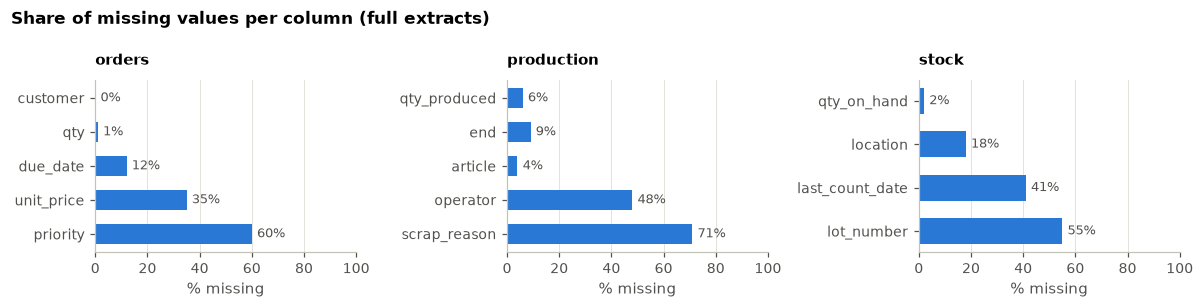

In [2]:
# @title 📊 Sample rows and missing values
prod = pd.DataFrame({
    "of_id": ["OF-1041", "OF-1042", "OF-1043", "OF-1043", "OF-1044", "OF-1045", "OF-1046", "OF-1047"],
    "article": ["SHAFT-20", "FLANGE-80", "BRKT-12", "BRKT-12", "SHAFT-20", "HSG-150", None, "FLANGE-80"],
    "machine": ["M-03", "M-07", "M-07", "M-07", "M-99", "M-03", "M-11", "M-07"],
    "start": ["2026-02-03 08:00", "2026-02-03 09:15", "03/02/2026 10:40", "03/02/2026 10:40",
              "2026-02-03 13:05", "2026-02-03 14:30", "2026-02-04 06:10", "2026-02-04 07:00"],
    "end": ["2026-02-03 09:05", "2026-02-03 08:50", "03/02/2026 12:10", "03/02/2026 12:10",
            "2026-02-03 15:00", None, "2026-02-04 07:40", "2026-02-04 09:30"],
    "qty_ordered": [50, 20, 200, 200, 50, 10, 30, 20],
    "qty_produced": [50, 20, 2000, 2000, 48, None, -30, 20],
    "status": ["Done", "Done", "Done", "Done", "done", "Done", "Done", "In progress"],
})
display(prod)

missing = {
    "orders":     {"customer": 0, "qty": 1, "due_date": 12, "unit_price": 35, "priority": 60},
    "production": {"qty_produced": 6, "end": 9, "article": 4, "operator": 48, "scrap_reason": 71},
    "stock":      {"qty_on_hand": 2, "location": 18, "last_count_date": 41, "lot_number": 55},
}
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), sharex=True)
for ax, (table, cols) in zip(axes, missing.items()):
    names, vals = list(cols), list(cols.values())
    ax.barh(names, vals, color=BLUE, height=0.6)
    for y, v in enumerate(vals):
        ax.text(v + 2, y, f"{v}%", va="center", fontsize=8.5, color=INK2)
    ax.set_title(f"{table}", fontsize=10)
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
    ax.set_xlabel("% missing")
fig.suptitle("Share of missing values per column (full extracts)", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

**Questions**
- What do you do first? Walk us through your first two days with this data.
- Which of these problems would you fix yourself, and which would you take back to the client?

#### A2 · A 50 GB file

The client exports two years of machine event logs as **one 50 GB CSV file**. Your laptop has 16 GB of RAM.

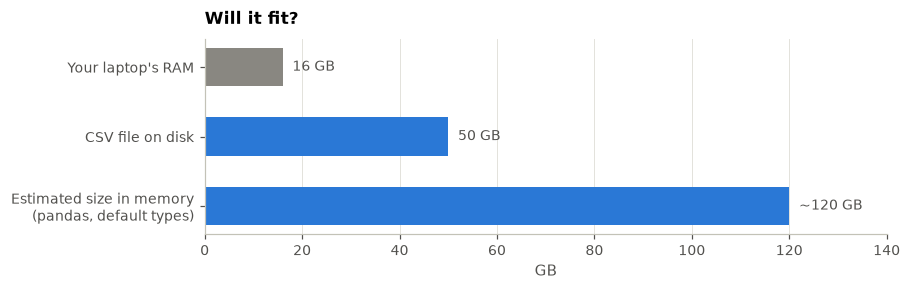

First lines of the file:

timestamp,machine_id,event,qty,spindle_rpm,operator_comment
2024-01-01 00:00:03,M-07,START,0,5980,
2024-01-01 00:00:41,M-02,PART_DONE,12,6120,
2024-01-01 00:01:18,M-07,ALARM,0,0,"Coolant low, refilled"
2024-01-01 00:01:55,M-11,PART_DONE,7,4410,


In [3]:
# @title 📊 Chart and first lines of the file
fig, ax = plt.subplots(figsize=(8, 2.3))
labels = ["Your laptop's RAM", "CSV file on disk", "Estimated size in memory\n(pandas, default types)"]
vals = [16, 50, 120]
ax.barh(labels, vals, color=[GRAY, BLUE, BLUE], height=0.55)
for y, v in enumerate(vals):
    ax.text(v + 2, y, f"{'~' if y == 2 else ''}{v} GB", va="center", fontsize=9, color=INK2)
ax.invert_yaxis(); ax.set_xlim(0, 140); ax.grid(axis="y", visible=False)
ax.set(xlabel="GB", title="Will it fit?")
plt.show()
print("First lines of the file:\n")
print("timestamp,machine_id,event,qty,spindle_rpm,operator_comment")
print("2024-01-01 00:00:03,M-07,START,0,5980,")
print("2024-01-01 00:00:41,M-02,PART_DONE,12,6120,")
print('2024-01-01 00:01:18,M-07,ALARM,0,0,"Coolant low, refilled"')
print("2024-01-01 00:01:55,M-11,PART_DONE,7,4410,")

**Questions**
- How do you load and process this file?
- Which tools or file formats would you consider? At what point would you stop working on your laptop?

##### 🧑‍💻 Exercise (optional): fill in the missing line
A small sample of the log (200,000 rows) is saved at `SAMPLE_LOG_PATH`. Pretend it does not fit in memory:
compute the **total quantity per machine** by reading the file in chunks.

In [4]:
def total_qty_per_machine(path, chunksize=50_000):
    totals = pd.Series(dtype="float64")
    for chunk in pd.read_csv(path, chunksize=chunksize, usecols=["machine_id", "qty"]):
        # TODO: aggregate this chunk and add the result to `totals`
        pass
    return totals.sort_index()

check_chunks(total_qty_per_machine)

⏳ Not implemented yet: `totals` is still empty.


### B. Evaluating a model

#### B1 · Splitting time-ordered data

You have **two years of placed orders** (weekly totals below). You want a model that forecasts the next 4 weeks of orders,
to support production decisions.

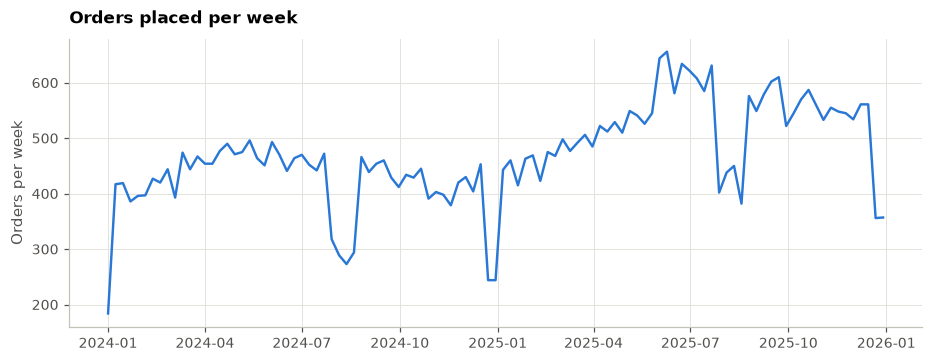

In [5]:
# @title 📊 Chart
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(ORDERS_WEEKLY.index, ORDERS_WEEKLY.values, color=BLUE, lw=1.6)
ax.set(title="Orders placed per week", ylabel="Orders per week")
plt.show()

**Questions**
- How do you split this data into training, validation and test sets? Why?
- What would go wrong with a random split?

##### 🧑‍💻 Try it (optional)
Set your split dates and run the cell to see your split on the chart.

In [6]:
train_end = None   # e.g. "YYYY-MM-DD": last day of the training data
val_end = None     # last day of the validation data (test = everything after)
show_split(train_end, val_end)

👉 Set train_end and val_end (e.g. 'YYYY-MM-DD'), then run the cell again.


#### B2 · 99% accuracy

You built a model that flags **defective parts** at the end of the production line.
On the test set (10,000 parts) it reaches **99.0% accuracy**. The quality manager wants to deploy it on Monday.

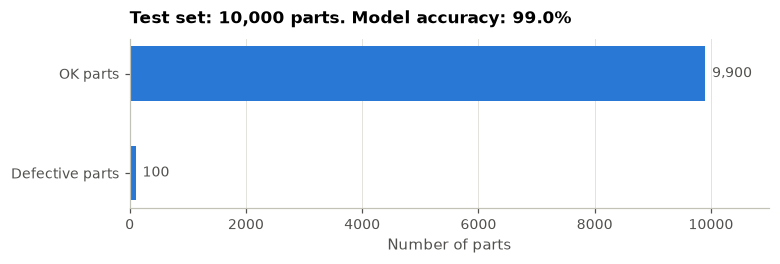

In [7]:
# @title 📊 Chart
fig, ax = plt.subplots(figsize=(7.5, 2))
counts = {"OK parts": int((Y_TRUE_QC == 0).sum()), "Defective parts": int((Y_TRUE_QC == 1).sum())}
ax.barh(list(counts), list(counts.values()), color=BLUE, height=0.55)
for y, v in enumerate(counts.values()):
    ax.text(v + 120, y, f"{v:,}", va="center", fontsize=9, color=INK2)
ax.invert_yaxis(); ax.set_xlim(0, 11000); ax.grid(axis="y", visible=False)
acc = (Y_TRUE_QC == Y_PRED_QC).mean()
ax.set(title=f"Test set: 10,000 parts. Model accuracy: {acc:.1%}", xlabel="Number of parts")
plt.show()

**Questions**
- Is the model ready for production? What would you check first?
- Which metrics would you use instead? How would you choose the decision threshold?

##### 🧑‍💻 Exercise (optional): implement two metrics

In [8]:
def precision_recall(y_true, y_pred):
    """y_true, y_pred: arrays of 0 (OK) and 1 (defective).
    Return (precision, recall) for the 'defective' class."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    # TODO
    return None, None

check_precision_recall(precision_recall)

⏳ Not implemented yet.


### C. In production

#### C1 · Good in testing, poor in production

Your duration model had a **test MAE of 12 min**. It went live on 2 March. Here is its weekly error in production.

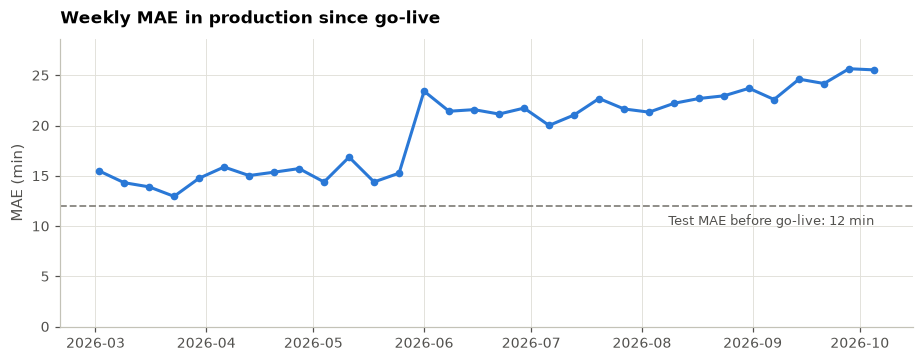

In [9]:
# @title 📊 Chart
rng = np.random.default_rng(14)
wk = pd.date_range("2026-03-02", periods=32, freq="W-MON")
i = np.arange(len(wk))
mae = 15 + rng.normal(0, 0.7, len(wk)) + 6.5 * (i >= 13) + 0.45 * np.clip(i - 22, 0, None)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(wk, mae, color=BLUE, marker="o", ms=4)
ax.axhline(12, color=GRAY, ls="--", lw=1.2)
ax.text(wk[-1], 11.2, "Test MAE before go-live: 12 min", color=INK2, fontsize=8.5, ha="right", va="top")
ax.set_ylim(0, max(mae) + 3)
ax.set(title="Weekly MAE in production since go-live", ylabel="MAE (min)")
plt.show()

**Questions**
- What could explain the gap between test and production performance? List as many causes as you can.
- What could cause a sudden jump, and what could cause a slow drift?
- How would you have detected this earlier? What would you put in place?

## Part 2: Operations Research. Scheduling a coating line

Same client. After machining, parts go through a **powder-coating machine** (it paints them).
We will build the problem in three steps. Each step is folded: we will unfold it together when it is time.

🖊️ Use the **Excalidraw** link from the Meet chat to sketch anything: models, trees, schedules...

### Version 0: one machine, minimize changeovers

The machine must process **8 jobs** (batches of parts). Each job $i$ has a **processing time** $p_i$.
Between two consecutive jobs $i \rightarrow j$, the machine needs a **changeover** (setup) of $s_{ij}$ minutes:
cleaning the paint circuit and/or changing the **fixture** (the rack that holds the parts).

Changeover rules, from the line supervisor:
- at least 5 min between any two jobs;
- going to a **darker** color is quick (+5 min per shade); going to a **lighter** color needs a full cleaning
  (+20 min, plus 10 min per shade). Shades, from light to dark: White → Yellow → Red → Blue → Black;
- changing the fixture (F1 ↔ F2) adds 15 min;
- the machine starts the shift clean, as if it had just finished a White job on fixture F1.

**Goal: find the order of the jobs that minimizes the total changeover time.**

job,1,2,3,4,5,6,7,8
color,Red,White,Black,Yellow,Blue,White,Red,Blue
fixture,F1,F2,F1,F1,F2,F1,F2,F1
processing time p (min),60,45,70,30,55,50,40,65


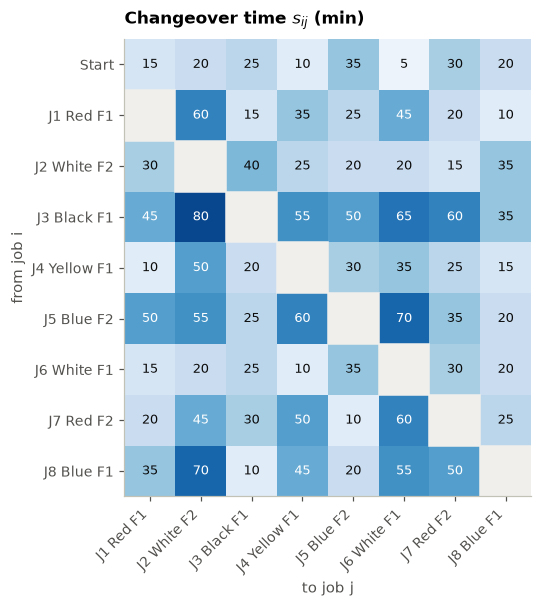

In [10]:
# @title 📊 The jobs and the changeover matrix
display(JOBS.loc[JOBS_V0, ["color", "fixture", "p_min"]].rename(columns={"p_min": "processing time p (min)"}).T)
rows = [START] + JOBS_V0
M = SETUP.loc[rows, JOBS_V0].astype(float)
fig, ax = plt.subplots(figsize=(7.6, 5.4))
im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=M.max().max() * 1.1)
for a in range(len(rows)):
    for b in range(len(JOBS_V0)):
        v = M.values[a, b]
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((b - 0.5, a - 0.5), 1, 1, color=LIGHT))
        else:
            ax.text(b, a, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v > 40 else INK)
lab = lambda j: f"J{j} {JOBS.at[j, 'color']} {JOBS.at[j, 'fixture']}"
ax.set_xticks(range(len(JOBS_V0)), [lab(j) for j in JOBS_V0], rotation=45, ha="right")
ax.set_yticks(range(len(rows)), ["Start"] + [lab(j) for j in JOBS_V0])
ax.set(xlabel="to job j", ylabel="from job i", title="Changeover time $s_{ij}$ (min)")
ax.grid(False)
plt.show()

**Playground.** Below is the planner's current order (the order in which jobs arrived).
Type any other order of the 8 jobs and run the cell to see the result.

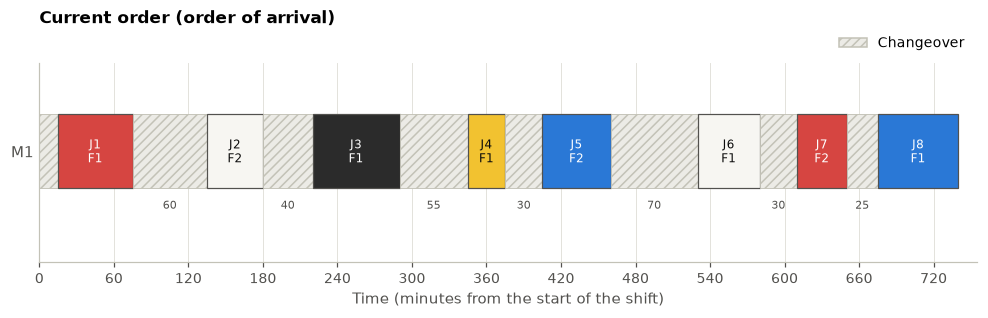

Total changeover time : 325 min
Makespan              : 740 min (when the last job finishes)


In [11]:
my_sequence = [1, 2, 3, 4, 5, 6, 7, 8]
show_schedule(my_sequence, title="Current order (order of arrival)")

**Questions**
1. How would you approach this problem? What are the **decisions**, the **objective**, the **constraints**?
2. How many possible orders are there for 8 jobs? For 50 jobs?
3. Does this problem remind you of a classic optimization problem?
4. How would you solve it **exactly**? Sketch a mathematical model (on the whiteboard or in the cell below).
5. How would you find a **good solution quickly**?

✍️ *Your notes (optional). Double-click to edit. LaTeX works, e.g. $\sum_{k=1}^{n} a_k \le b$.*

#### Inside a MIP solver
You give a model of this problem, with **30 jobs**, to a MIP solver. Here is what it reports while it runs.

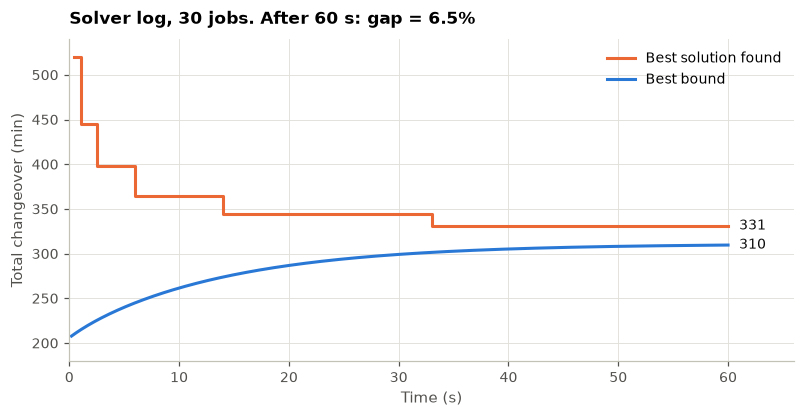

In [12]:
# @title 📊 Solver progress (illustrative)
t_inc = [0.4, 1.1, 2.5, 6.0, 14.0, 33.0, 60.0]
v_inc = [520, 445, 398, 365, 344, 331, 331]
t = np.linspace(0.2, 60, 400)
bound = 210 + 101 * (1 - np.exp(-t / 14)) - 4 * np.exp(-t / 2)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.step(t_inc, v_inc, where="post", color=ORANGE, label="Best solution found")
ax.plot(t, bound, color=BLUE, label="Best bound")
ax.text(61, v_inc[-1], f"{v_inc[-1]}", va="center", color=INK, fontsize=9)
ax.text(61, bound[-1], f"{bound[-1]:.0f}", va="center", color=INK, fontsize=9)
gap = (v_inc[-1] - bound[-1]) / v_inc[-1]
ax.set(xlabel="Time (s)", ylabel="Total changeover (min)", xlim=(0, 66), ylim=(180, 540),
       title=f"Solver log, 30 jobs. After 60 s: gap = {gap:.1%}")
ax.legend(loc="upper right")
plt.show()

**Questions**
6. What do these two curves represent? Why does a solver track two numbers?
7. Where does the lower curve come from? Explain how a MIP solver works.
8. The solver stops after 60 s. What do you know about the quality of the solution it returns?

#### 🧑‍💻 Exercise (optional): a constructive heuristic
Complete the function: starting from the machine's start state, repeatedly pick the job not yet scheduled
with the **smallest changeover** from the current job. Useful: `setup_time(i, j)` and `START`.

Then: what is its complexity? Is the result optimal? How would you improve it?

In [13]:
def nearest_neighbor(jobs):
    sequence, current, remaining = [], START, set(jobs)
    while remaining:
        # TODO: pick `nxt`, the remaining job with the smallest setup_time(current, nxt),
        #       then add it to `sequence`, remove it from `remaining` and update `current`
        break
    return sequence

check_nearest_neighbor(nearest_neighbor(JOBS_V0))

⏳ Not implemented yet: the function returns an empty sequence.


### Version 1: add due dates

Each job now has a **due date** $d_i$, in minutes from the start of the shift.
The client also wants to maximize **OTD** (*On-Time Delivery*: the share of jobs finished by their due date).

job,1,2,3,4,5,6,7,8
color,Red,White,Black,Yellow,Blue,White,Red,Blue
fixture,F1,F2,F1,F1,F2,F1,F2,F1
processing time p (min),60,45,70,30,55,50,40,65
due date d (min),300,480,600,120,330,600,420,270


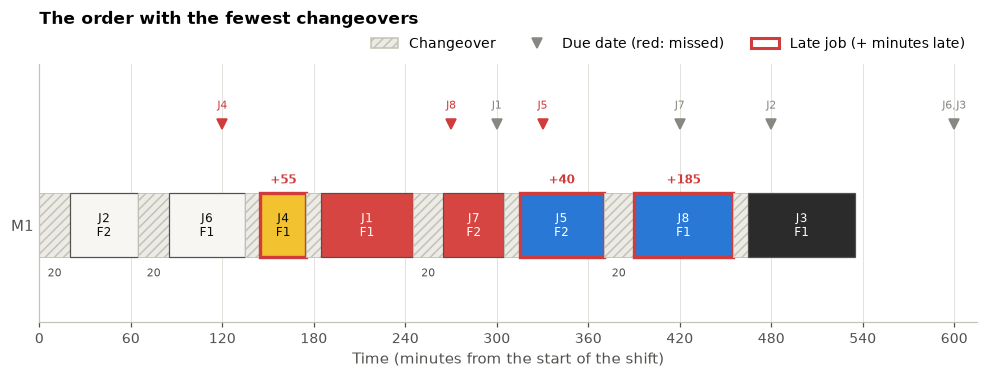

Total changeover time : 120 min
Makespan              : 535 min (when the last job finishes)
On-time jobs          : 5 / 8  (OTD = 62%)
Total tardiness       : 280 min
Late jobs             : J4 (+55), J5 (+40), J8 (+185)


In [14]:
# @title 📊 Due dates, and the order with the fewest changeovers
display(JOBS.loc[JOBS_V0, ["color", "fixture", "p_min", "due_min"]]
        .rename(columns={"p_min": "processing time p (min)", "due_min": "due date d (min)"}).T)
show_schedule([2, 6, 4, 1, 7, 5, 8, 3], due_dates=True, title="The order with the fewest changeovers")

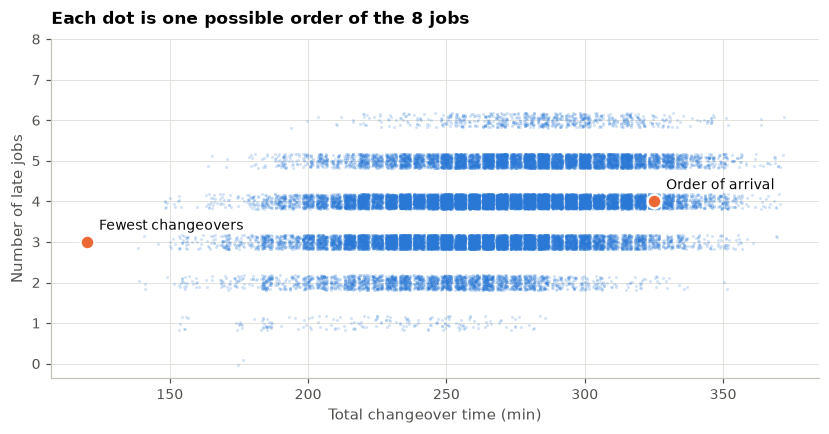

In [15]:
# @title 📊 All 40,320 possible orders
import itertools
perms = np.array(list(itertools.permutations(JOBS_V0)))
prev = np.c_[np.full(len(perms), START), perms[:, :-1]]
S = SETUP.to_numpy()                      # S[i, j - 1] = changeover from i to j
s_mat = S[prev, perms - 1]
ends = np.cumsum(s_mat + np.vectorize(P.get)(perms), axis=1)
late = (ends > np.vectorize(DUE.get)(perms)).sum(axis=1)
total_setup = s_mat.sum(axis=1)
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(total_setup + rng.uniform(-2, 2, len(perms)), late + rng.uniform(-0.18, 0.18, len(perms)),
           s=4, color=BLUE, alpha=0.2, lw=0)
marks = {"Order of arrival": [1, 2, 3, 4, 5, 6, 7, 8], "Fewest changeovers": [2, 6, 4, 1, 7, 5, 8, 3]}
for name, seq in marks.items():
    e = evaluate(seq)
    x, yv = e.setup.sum(), (e.tardiness > 0).sum()
    ax.plot(x, yv, marker="o", ms=9, color=ORANGE, mec="white", mew=1.5, ls="none")
    ax.annotate(name, (x, yv), xytext=(8, 8), textcoords="offset points", fontsize=9, color=INK)
ax.set(xlabel="Total changeover time (min)", ylabel="Number of late jobs",
       title="Each dot is one possible order of the 8 jobs")
ax.set_yticks(range(0, 9))
plt.show()

**Playground.** Same as before, now with due dates.

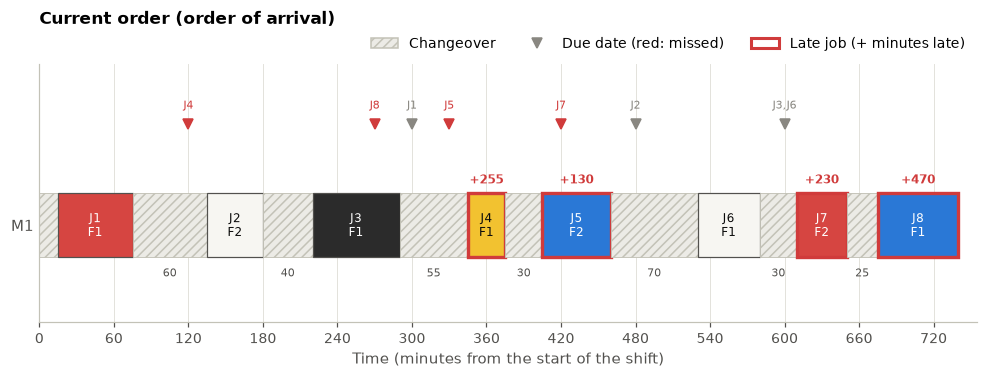

Total changeover time : 325 min
Makespan              : 740 min (when the last job finishes)
On-time jobs          : 4 / 8  (OTD = 50%)
Total tardiness       : 1085 min
Late jobs             : J4 (+255), J5 (+130), J7 (+230), J8 (+470)


In [16]:
my_sequence = [1, 2, 3, 4, 5, 6, 7, 8]
show_schedule(my_sequence, due_dates=True, title="Current order (order of arrival)")

**Questions**
1. How does the order of the jobs now affect the result? What new quantities must your model compute?
2. How do you define "late"? Which objective would you optimize, and how would you write it?
3. Changeovers vs. on-time delivery: how do you handle **two objectives**? Which dot of the chart would you pick?
4. Which simple rule would build a good order quickly? Does your improvement method from Version 0 still work?

#### 🧑‍💻 Exercise (optional): spot the bug
This function should return the **total tardiness** (total minutes late) of a sequence.
Run it: are the results plausible? Find and fix the bug.

In [17]:
def total_tardiness(sequence):
    t, prev, total = 0, START, 0
    for j in sequence:
        t += setup_time(prev, j) + P[j]   # completion time of job j
        total += t - DUE[j]               # minutes late for job j
        prev = j
    return total

print("Order of arrival   :", total_tardiness([1, 2, 3, 4, 5, 6, 7, 8]), "min")
print("Fewest changeovers :", total_tardiness([2, 6, 4, 1, 7, 5, 8, 3]), "min")

Order of arrival   : 230 min
Fewest changeovers : -835 min


### Version 2: several machines

Business is growing: this shift has **12 jobs** (4 new ones, J9 to J12), and the plant installed a **second coating machine**,
identical to the first one (same changeover rules, same start state).
You now decide **which machine** processes each job, **and in which order**.

In [18]:
# @title 📊 The 4 new jobs
display(JOBS.loc[[9, 10, 11, 12], ["color", "fixture", "p_min", "due_min"]]
        .rename(columns={"p_min": "processing time p (min)", "due_min": "due date d (min)"}).T)

job,9,10,11,12
color,Yellow,Black,White,Red
fixture,F2,F2,F1,F1
processing time p (min),50,45,35,55
due date d (min),150,240,90,210


**Playground.** The planner's current plan alternates jobs between the two machines. Try your own plan.

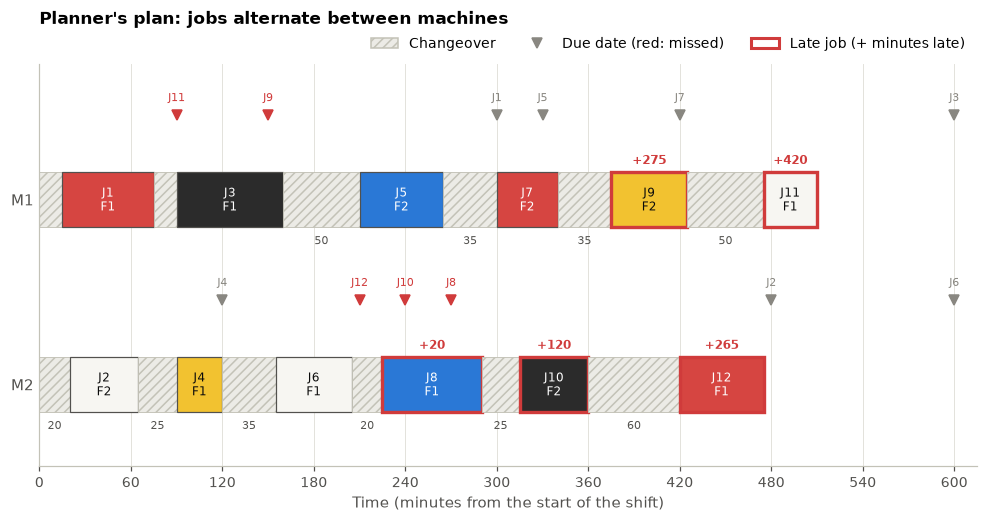

Total changeover time : 385 min
Makespan              : 510 min (when the last job finishes)
   M1: 6 jobs, busy until 510 min, changeovers 200 min
   M2: 6 jobs, busy until 475 min, changeovers 185 min
On-time jobs          : 7 / 12  (OTD = 58%)
Total tardiness       : 1100 min
Late jobs             : J9 (+275), J11 (+420), J8 (+20), J10 (+120), J12 (+265)


In [19]:
my_plan = {"M1": [1, 3, 5, 7, 9, 11],
           "M2": [2, 4, 6, 8, 10, 12]}
show_schedule(my_plan, due_dates=True, title="Planner's plan: jobs alternate between machines")

**Questions**
1. Which decisions do you need to make now? Which classic problem does it remind you of?
2. How would you extend your model (variables, constraints)?
3. The client cares about changeovers, on-time delivery and a **balanced load** between machines. How do you handle all three?
4. Propose a heuristic: how do you build a first plan, and how do you improve it?
5. A MIP solves this instance in seconds. The real plant schedules **300 jobs per week on 12 machines**, and the solver
   does not finish in an hour. What do you do?

## Part 3: Applied AI. An assistant for the planner

Same coating line, two machines, the 12 jobs of Version 2. The plant wants planners to change the plan
by simply **typing what they need** in a chat window, instead of editing it by hand.

### The request

It is 7:55. The plan below starts at 8:00 (minute 0). The planner types in the chat:

> *"The customer of J9 just called: they now need it by minute **100**, not 150.
> Update the plan, but don't add more than 15 minutes of changeovers."*

*(Running the cell below changes J9's due date to 100 for the rest of the notebook.)*

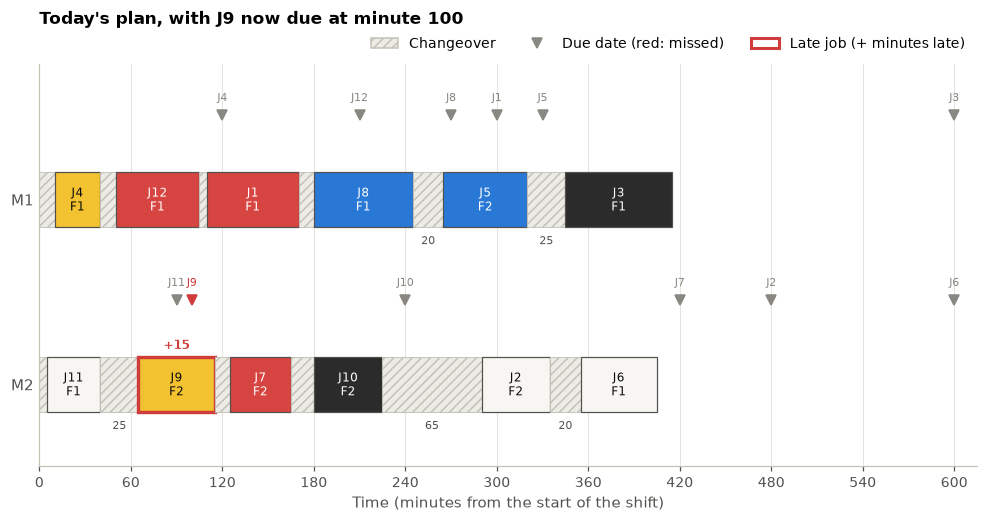

Total changeover time : 220 min
Makespan              : 415 min (when the last job finishes)
   M1: 6 jobs, busy until 415 min, changeovers 80 min
   M2: 6 jobs, busy until 405 min, changeovers 140 min
On-time jobs          : 11 / 12  (OTD = 92%)
Total tardiness       : 15 min
Late jobs             : J9 (+15)


In [20]:
# @title 📊 Today's plan, with J9's new due date
DUE[9] = 100    # the customer's new request (it was 150)
TODAY_PLAN = {"M1": [4, 12, 1, 8, 5, 3],
              "M2": [11, 9, 7, 10, 2, 6]}
show_schedule(TODAY_PLAN, due_dates=True, title="Today's plan, with J9 now due at minute 100")

**Playground.** Try to answer the planner yourself.

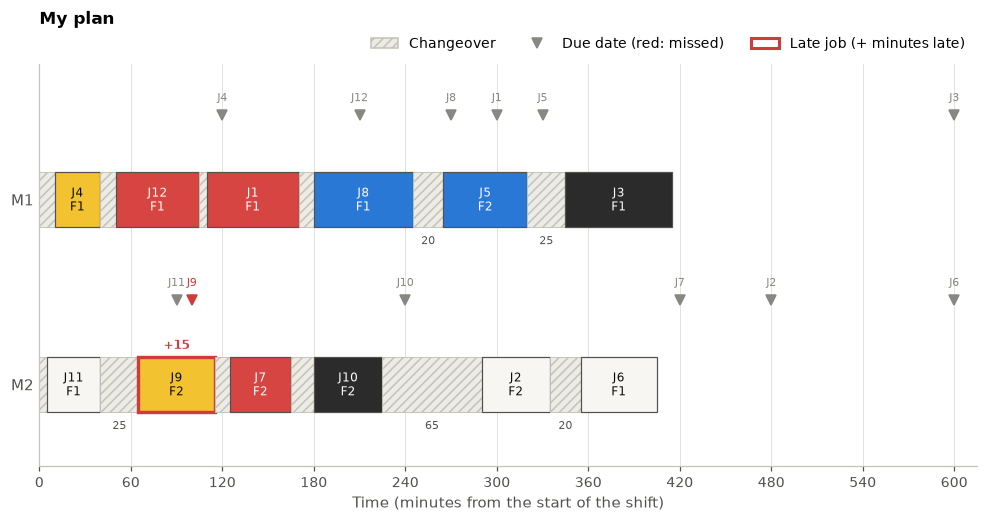

Total changeover time : 220 min
Makespan              : 415 min (when the last job finishes)
   M1: 6 jobs, busy until 415 min, changeovers 80 min
   M2: 6 jobs, busy until 405 min, changeovers 140 min
On-time jobs          : 11 / 12  (OTD = 92%)
Total tardiness       : 15 min
Late jobs             : J9 (+15)


In [21]:
DUE[9] = 100    # J9's new due date
my_plan = {"M1": [4, 12, 1, 8, 5, 3],
           "M2": [11, 9, 7, 10, 2, 6]}
show_schedule(my_plan, due_dates=True, title="My plan")

**Questions**
1. How would you build this assistant? Sketch its main parts on the whiteboard.
   What does the language model (LLM) do, and what should it **not** do?
2. Can the planner's request be met? What should the assistant answer if it cannot?
3. How do you make sure a plan is correct before the planner sees it?
4. Before 20 planners use it, how do you test it? Once it is live, what do you measure?

#### 🧑‍💻 Exercise (optional): check the assistant's output
The assistant returns its plan as JSON, for example `{"M1": [4, 12, 1], "M2": [11, 9]}`.
Before showing it to the planner, check that it is a **valid plan**: known machines, known jobs,
every job scheduled exactly once.

Then: what else would you check before showing the plan to the planner?

In [22]:
def validate_plan(plan, jobs=JOBS_V2, machines=("M1", "M2")):
    """plan: a dict {machine: list of job ids}, as returned by the assistant.
    Return a list of problems (strings). An empty list means the plan is valid."""
    problems = []
    # TODO
    return problems

check_validate_plan(validate_plan)

⏳ Not implemented yet: no problem is reported.


---
## The end: thank you! 🙌
Any questions for us?